In [2]:

import sqlite3

import pandas as pd

In [3]:
# Connect to our existing database
conn = sqlite3.connect("california_housing.db")

In [4]:
# Retrieve observations
query = """
SELECT *
FROM housing;
"""

In [5]:
df = pd.read_sql_query(query, conn)

conn.close()

In [6]:
# Inspect the dataset
print("Dataset shape:", df.shape)
print(df.head())
print(df.info())
print(df.isnull().sum())

Dataset shape: (20640, 9)
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64


In [7]:
# Training dataset 
X = df.drop(columns = ["MedHouseVal"])
y = df["MedHouseVal"]

print("Features shape (X):", X.shape)
print("Target shape (y):", y.shape)
print("\nFeature Names:")
print(X.columns.tolist())

Features shape (X): (20640, 8)
Target shape (y): (20640,)

Feature Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [8]:
# For OLS regression,
# We dont have to do scaling of features, 
# As the coefficients will be adjusted accordingly.

In [9]:
# Train-test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
                                                    X,
                                                    y, 
                                                    test_size=0.2, 
                                                    random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (16512, 8)
X_test shape: (4128, 8)
y_train shape: (16512,)
y_test shape: (4128,)


In [10]:
# Train the model
from sklearn.linear_model import LinearRegression

# Intialize the model
model = LinearRegression()

# Train using the training data
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [14]:
# Inspect the model intercepts
print("Model intercept:", model.intercept_)

# print model coefficients with feature names
print("\nModel coefficients")
print("------------------")
for feature, coef in zip(X.columns, model.coef_):
    print(f"{feature}: {coef}")

Model intercept: -37.023277706064256

Model coefficients
------------------
MedInc: 0.4486749096657182
HouseAge: 0.009724257517905063
AveRooms: -0.12332334282795991
AveBedrms: 0.783144906792973
Population: -2.029620580092512e-06
AveOccup: -0.0035263184871344028
Latitude: -0.41979248658836005
Longitude: -0.43370806496398817


In [ ]:
# Suppose the learned coefficient for MedInc is positive, 
# while the coefficient for HouseAge is negative.

# Can we conclude that increasing median income causes 
# housing prices to rise and 
# increasing house age causes prices to fall? 
# Why or why not?

# Answer:
# Higher median income is associated with higher predicted house values, 
# holding other model features constant.
# However, this does not imply causation.
# Regression coefficients describe conditional associations, 
# not necessarily causal effects.

In [15]:
# Generate predictions on the test set

# Predict on unseen test data
y_pred = model.predict(X_test)

# Compare actual vs predicted values
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

print(results.head(10))

    Actual  Predicted
0  0.47700   0.719123
1  0.45800   1.764017
2  5.00001   2.709659
3  2.18600   2.838926
4  2.78000   2.604657
5  1.58700   2.011754
6  1.98200   2.645500
7  1.57500   2.168755
8  3.40000   2.740746
9  4.46600   3.915615


In [16]:
# Evaluate the model performance
# Using metrics such as Mean Squared Error (MSE), 
# Root Mean Squared Error (RMSE), 
# and R-squared (R²) to assess the model's accuracy.


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: ${mae * 100000:,.2f}")
print(f"RMSE: ${rmse * 100000:,.2f}")
print(f"R²: {r2:.4f}")


MAE: $53,320.01
RMSE: $74,558.14
R²: 0.5758


In [17]:
# Interview question
# If RMSE is significantly larger than MAE, 
# what does that tell us about the model's prediction errors?

# Answer:
# If RMSE is significantly larger than MAE, 
# it indicates that the model have substantial prediction errors
# on some observations, which are likely outliers.
# To confirm this, we hade 
# to do further analyis, like plot residual distribution 

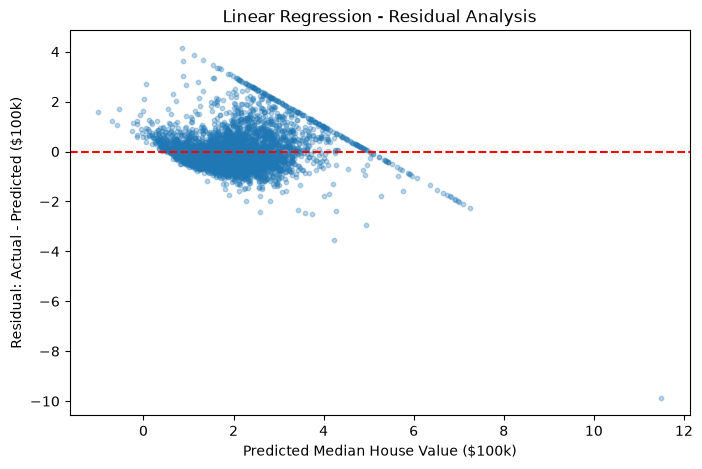

In [18]:
# Residual analysis


import matplotlib.pyplot as plt

residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.3, s=10)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Median House Value ($100k)")
plt.ylabel("Residual: Actual - Predicted ($100k)")
plt.title("Linear Regression - Residual Analysis")
plt.show()


In [19]:
# Observation	
# (Interpretation)
# Dense cluster around predicted values of 1–3 
# (Most predictions are concentrated in this range)
# Diagonal upper boundary	
# (Consistent with the California Housing target cap near $500,000
# Changing residual spread	
# (Possible heteroscedasticity (nonconstant error variance))
# Extreme residual near −10	
# (A substantial overprediction)
# Nonrandom residual structure	
# (Possible model misspecification)

In [ ]:
# Interview Question
# Your Linear Regression model has an R² of 0.5758, 
# and its residual plot shows nonconstant variance and 
# a few extreme prediction errors. 
# What would you investigate before switching to Random Forest or XGBoost?

# Answer:
# Before switching to Random Forest or XGBoost,
# I would investigate the following:
# 1. Feature engineering: Exploring non-linear relationships 
# and interactions between features and potential redundant features. 
# 2. Outlier detection and treatment: Identifying and handling
# extreme values that may be affecting model performance.
# 3. Check for heteroscedasticity: If the variance of residuals is not constant,
# it may indicate that the model is not capturing some underlying patterns in the data.
# 4. Check for Capped target variable: If the target variable is capped,
# it may be necessary to transform the target variable or 
# use a different modeling approach.
# 5. Check for multicollinearity: Ensuring that features are not highly correlated,
# which can affect the stability of the model coefficients.